# v8 - Canal piloto Yaqui: STIV sobre un video de movil reenviado por WhatsApp

Mide la velocidad superficial de un canal de riego a partir de un video grabado **a pulso con un
movil** desde una pasarela y reenviado por WhatsApp, con el STIV de la v7. Es el caso con menos
informacion de toda la serie: **ningun dato de campo**, ni puntos de control, ni medida alguna, ni
referencia. Y la imagen es la peor: 1024x576 a **661 kb/s**, un bitrate al que el codificador aplana
el agua turbia y deja como textura artefactos de bloque **fijos a la rejilla de pixeles**, que no se
mueven con el agua.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v7 llevan la marca `# [v8]`.

---
## Que cambia respecto a v7

| Parte | v7 (Arrow) | v8 (canal Yaqui) | Por que lo obliga este caso |
|---|---|---|---|
| 0-1 | dos videos ortorrectificados | un video de movil, en perspectiva | es lo que hay |
| 2 | escala dada, sin rectificar | **orillas** detectadas (gradiente + RANSAC), **punto de fuga** y la **homografia de la v4** con una focal supuesta; el mapa de rectificacion de la v5 | camara oblicua sin ninguna medida: como la v4, pero sin hiladas de muro; las orillas hacen su papel |
| 4 | gris -> rectificar -> antialias | gris -> **top-hat** -> **estabilizar** -> rectificar -> antialias | el codec deja textura fija que no viaja con el agua; el movil se mueve ~7 px |
| 4 | `N_FRAMES` = 600 (los videos eran mas cortos) | **el video entero** (2429 fotogramas, 81 s) | trazador escaso: mas tiempo, mas detritos por linea (la misma razon que en la v6) |
| 4 | `LADO_BLOQUE` = 24 | `LADO_BLOQUE` = **64** | el 24 respondia a los 99 fotogramas de la v7 |
| 4 | votan todos los bloques | votan solo los bloques **con particula** (el 15 % mas brillante, `CUANTIL_SENAL`) | sin esa seleccion el residuo estatico tira de la mediana hacia pendiente 0: las estaciones con trazador salen mas lentas (medido abajo) |
| 4b | coherencia >= 0.70; brillo y contraste desactivados | coherencia >= **0.60** y **densidad de trazador** entre 0.004 y 0.05 | la coherencia del agua con detritos (0.63-0.78) y sin ellos (0.26-0.52) deja el hueco por debajo de 0.70; la densidad separa agua sin trazador y orilla de hormigon |
| 5 | m/s | alturas de camara/s, y m/s con un **ancho supuesto** de 5 m | no hay ninguna longitud medida |
| 4c, 7 | decorrelacion y PIV ensemble | (no aplican) | sin referencia ni experimento de control |

**Lo que no cambia:** `construir_sti` en una pasada con `MAPA_RECT`, `mapa_lineas` y `mapa_banda`
(banda normalizada y promediada), la cobertura por muestra, `preparar_sti`, el tensor con
diferencias centrales y `SIGMA_DERIVADA` = 1.5, `COH_MIN_BLOQUE` = 0.50, `medir_video` y el modulo
`benchmark`.

> Diferencia con `casos/08_canal_piloto_yaqui`: aquel notebook termina en un video de presentacion y
> completa las estaciones sin trazador con un modelo de seccion (Shiono-Knight). Ni lo uno ni lo
> otro es velocimetria: aqui la medida termina donde termina la medida.

---
## Parte 0 - Rutas de trabajo

El video esta en `datos/canal_riego/` del workspace.

In [1]:
import os
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
ARCHIVO_VIDEO = Path("../../datos/canal_riego/WhatsApp Video 2026-08-16 at 8.07.12 PM.mp4")  # [v8]

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # velocidad estacion por estacion
SALIDA_RESUMEN = DIR_SALIDA / "resumen.csv"                # tabla final (no hay caudal)
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada.
for entrada in (ARCHIVO_VIDEO,):                                                     # [v8]
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Salidas en:       salidas
  OK    WhatsApp Video 2026-08-16 at 8.07.12 PM.mp4


---
## Parte 1 - Lectura del video

1024x576 a ~30 fps, 81 s. La camara esta sobre una pasarela, mirando aguas abajo por el eje del
canal, y el agua se aleja de ella (hacia arriba en la imagen).

Dimensiones del fotograma: (576, 1024, 3)
FPS del video: 29.9753  ->  DT = 33.361 ms
Fotogramas en el video: 2429


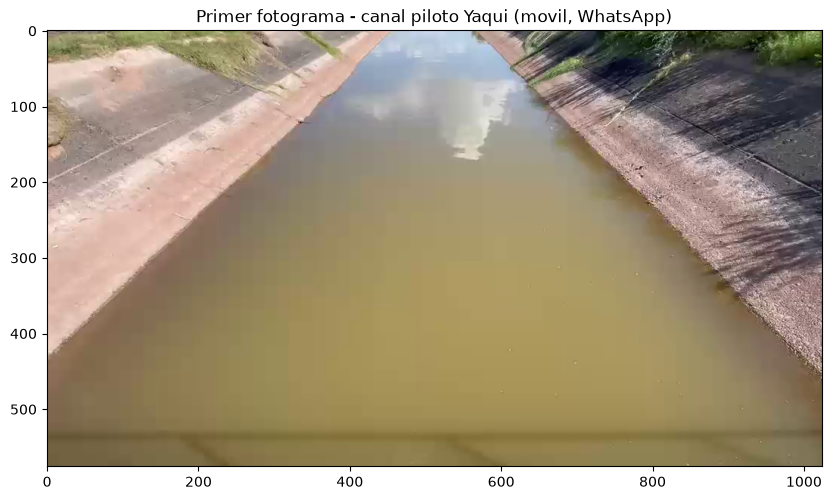

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# OpenCV: los metadatos y el primer fotograma del video que se mide.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
ALTO_PX, ANCHO_PX = frame.shape[:2]
gris0 = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)                                  # [v8]

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")
print(f"Fotogramas en el video: {N_TOTAL}")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - canal piloto Yaqui (movil, WhatsApp)")                 # [v8]
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Geometria: orillas, punto de fuga y rectificacion

Como en la v4 no hay puntos de control ni ninguna medida, y la rectificacion sale del **punto de
fuga** del eje del canal. Alli lo daban las hiladas de los muros; aqui lo dan **las dos orillas**: en
cada fila se busca el maximo gradiente horizontal en cada mitad de la imagen, se ajusta una recta a
cada orilla con RANSAC (los puntos de vegetacion o de reflejos quedan fuera), y las dos rectas, que
son paralelas en el mundo, se cortan en el punto de fuga.

A partir de ahi la **homografia es la de la v4** (balanceo nulo, focal supuesta, la altura de la
camara como unidad), y el plano rectificado se construye como **mapa** con `remap`, como en la v5.

La focal no se puede medir: WhatsApp reencodea y no queda EXIF. 780 px son ~26 mm equivalentes,
la camara principal tipica de un movil. Al contrario que en la v4, aqui **no es cosmetica**: de 700 a
900 px la velocidad cambia +-9 %.

Un aviso: que el canal salga de ancho constante en el plano rectificado **no valida nada**, porque el
punto de fuga es la interseccion de las dos orillas. Lo que si valida la geometria es que las
estelas de la STI salgan **rectas**: con un horizonte equivocado, una particula a velocidad constante
dibujaria una curva.

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Geometria                                                       [v8]
# ---------------------------------------------------------------------------------------
FOCAL = 780.0                 # px, supuesta (ver arriba): la mayor incertidumbre geometrica
# Filas donde se buscan las orillas: por debajo de 560 empieza la pasarela; por encima de
# 60 el canal ya no se distingue del fondo.
FILA_BORDE_INI, FILA_BORDE_FIN, FILA_BORDE_PASO = 60, 560, 10
# Tramo medido, en alturas de camara desde la camara: por debajo de 1.40 esta la sombra de
# la pasarela; por encima de 3.20 el muestreo cae por debajo de ~0.2 px de imagen y la STI
# se aliasea (medido en archivo/08_canal_piloto_yaqui/experimentos/alcance/).
YMIN, YMAX = 1.40, 3.20
# ---------------------------------------------------------------------------------------


def recta_ransac(P, tol=6.0, iters=600):
    """[v8] Recta x = a*y + b robusta a puntos sueltos."""
    rng = np.random.default_rng(0)
    mejor = (0, 0.0, 0.0)
    for _ in range(iters):
        (x1, y1), (x2, y2) = P[rng.choice(len(P), 2, replace=False)]
        if abs(y1 - y2) < 20:
            continue
        a = (x1 - x2) / (y1 - y2)
        n = (np.abs(P[:, 0] - (a * P[:, 1] + x1 - a * y1)) < tol).sum()
        if n > mejor[0]:
            mejor = (n, a, x1 - a * y1)
    m = np.abs(P[:, 0] - (mejor[1] * P[:, 1] + mejor[2])) < tol
    a, b = np.polyfit(P[m, 1], P[m, 0], 1)
    return float(a), float(b), int(m.sum())


# [v8] Las orillas: maximo gradiente horizontal fila a fila, en cada mitad de la imagen.
izq, der = [], []
for y in range(FILA_BORDE_INI, FILA_BORDE_FIN, FILA_BORDE_PASO):
    fila = cv2.GaussianBlur(gris0[y:y + 1, :].astype(np.float32), (9, 1), 0).ravel()
    d = np.abs(np.diff(fila))
    izq.append((int(np.argmax(d[:ANCHO_PX // 2])), y))
    der.append((int(ANCHO_PX // 2 + np.argmax(d[ANCHO_PX // 2:])), y))
a_izq, b_izq, n_izq = recta_ransac(np.array(izq, float))
a_der, b_der, n_der = recta_ransac(np.array(der, float))
# El punto de fuga: donde se cortan las dos orillas.
y_v = (b_der - b_izq) / (a_izq - a_der)
V1 = np.array([a_izq * y_v + b_izq, y_v])
print(f"Orillas: {n_izq} y {n_der} puntos de 50 en la recta; punto de fuga ({V1[0]:.1f}, {V1[1]:.1f})")


def homografia(v1, focal, xmin, ymax, esc):
    """Imagen -> plano rectificado (px), con la altura de la camara como unidad (de la v4)."""
    cxi, cyi = ANCHO_PX / 2, ALTO_PX / 2
    theta = np.arctan((cyi - v1[1]) / focal)                 # cabeceo, del horizonte
    K = np.array([[focal, 0, cxi], [0, focal, cyi], [0, 0, 1.0]])
    R = np.array([[1, 0, 0],
                  [0, -np.sin(theta), -np.cos(theta)],
                  [0, np.cos(theta), -np.sin(theta)]])
    g2i = K @ np.column_stack([R[:, 0], R[:, 1], [0, np.cos(theta), np.sin(theta)]])
    d = R.T @ np.linalg.inv(K) @ np.array([v1[0], v1[1], 1.0])
    psi = np.arctan2(d[0], d[1])                             # guinada: canal vertical en la salida
    rot = np.array([[np.cos(psi), np.sin(psi), 0],
                    [-np.sin(psi), np.cos(psi), 0], [0, 0, 1.0]])
    S = np.array([[esc, 0, -xmin * esc], [0, -esc, ymax * esc], [0, 0, 1.0]])
    return S @ np.linalg.inv(g2i @ np.linalg.inv(rot)), np.degrees(theta), np.degrees(psi)


# [v8] Donde caen las orillas en el plano (con una escala provisional de 1 px por altura):
# fija el ancho del canal, en alturas de camara, y el recorte transversal.
H1, CABECEO, GUINADA = homografia(V1, FOCAL, 0.0, YMAX, 1.0)
ys_b = np.linspace(FILA_BORDE_INI + 60, FILA_BORDE_FIN - 40, 9)
def a_plano(P):
    q = cv2.perspectiveTransform(np.float32(P).reshape(-1, 1, 2), H1).reshape(-1, 2)
    return q[:, 0]                                           # X (con xmin = 0 y esc = 1)
X_IZQ = float(np.mean(a_plano(np.column_stack([a_izq * ys_b + b_izq, ys_b]))))
X_DER = float(np.mean(a_plano(np.column_stack([a_der * ys_b + b_der, ys_b]))))
ANCHO_CANAL = X_DER - X_IZQ
print(f"cabeceo {CABECEO:.2f} grados, guinada {GUINADA:.2f} grados; ancho del canal "
      f"{ANCHO_CANAL:.4f} alturas de camara")

Orillas: 35 y 18 puntos de 50 en la recta; punto de fuga (519.0, -53.1)
cabeceo 23.62 grados, guinada 0.47 grados; ancho del canal 2.2504 alturas de camara


---
## Parte 3 - Lineas de busqueda

15 estaciones entre las orillas, dejando 0.10 alturas de camara de **retranqueo** en cada lado (la
franja pegada a la orilla derecha es hormigon mojado). Cada una es una **banda de 11 lineas**
paralelas de 0.10 de ancho: con un trazador tan escaso una sola linea casi nunca ve una particula.

La resolucion del plano rectificado se elige para que **un pixel sea el desplazamiento esperado por
fotograma**, o sea `DS` = 1 px: asi el paso de muestreo es el optimo de siempre sin interpolar mas de
lo necesario.

Plano rectificado: 1418x963 px a 535 px por altura de camara; DS = 1 px
15 estaciones x 11 lineas de 962 muestras; cobertura minima 1.00


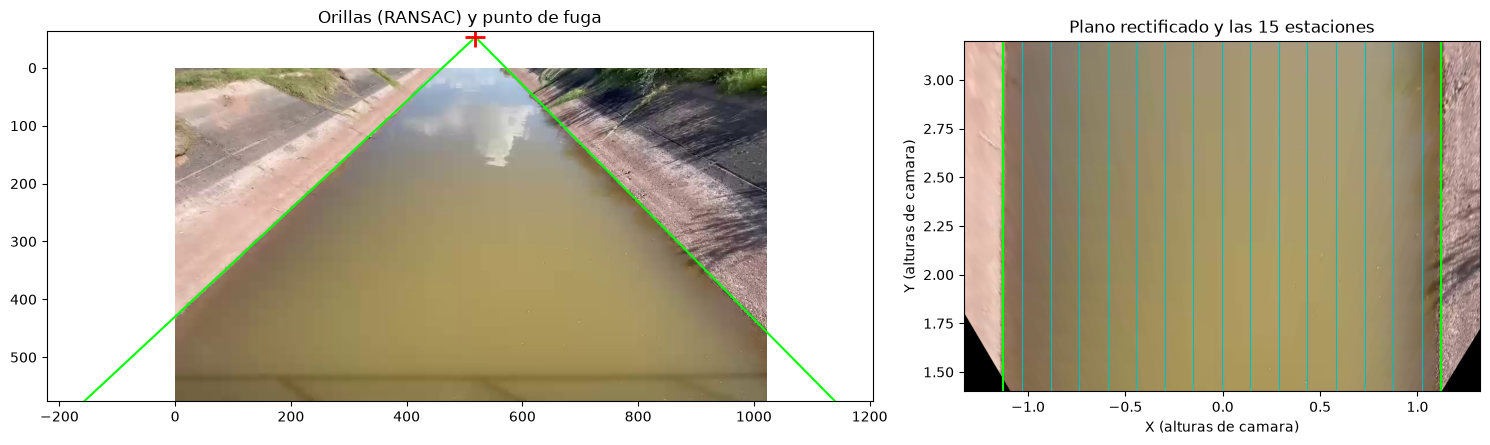

In [4]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda                                              [v8]
# ---------------------------------------------------------------------------------------
# Velocidad esperada en alturas de camara por segundo. Solo fija el paso de muestreo; sale de
# una correlacion de conjunto previa (0.038), redondeada al alza tras ver las estelas.
V_ESPERADA = 0.056
# Estaciones y retranqueo desde cada orilla (la franja de la orilla derecha es hormigon).
N_ESTACIONES = 15
RETRANQUEO = 0.10
# Direccion del flujo en el plano rectificado: hacia arriba (el agua se aleja de la camara).
ANGULO_FLUJO = -90.0
# Banda de 11 lineas paralelas de 0.10 alturas de camara: con 3 lineas la coherencia cae a
# 0.48-0.75; con 21 no mejora.
ANCHO_BANDA_ALT, N_LINEAS_BANDA = 0.10, 11
# ---------------------------------------------------------------------------------------

# [v8] El plano rectificado, con 1 px = desplazamiento esperado por fotograma.
ESC = 1.0 / (V_ESPERADA * DT)                    # px por altura de camara
ESCALA = 1.0 / ESC                               # alturas de camara por px
XMIN, XMAX = X_IZQ - 0.2, X_DER + 0.2
HOMOGRAFIA, _, _ = homografia(V1, FOCAL, XMIN, YMAX, ESC)
TAM_RECT = (int((XMAX - XMIN) * ESC), int((YMAX - YMIN) * ESC))
jj, ii = np.meshgrid(np.arange(TAM_RECT[0], dtype=np.float32), np.arange(TAM_RECT[1], dtype=np.float32))
q = cv2.perspectiveTransform(np.stack([jj.ravel(), ii.ravel()], 1).reshape(-1, 1, 2),
                             np.linalg.inv(HOMOGRAFIA)).reshape(TAM_RECT[1], TAM_RECT[0], 2)
MAPA_RECT = (np.ascontiguousarray(q[..., 0]), np.ascontiguousarray(q[..., 1]))

X_ESTACIONES = np.linspace(X_IZQ + RETRANQUEO, X_DER - RETRANQUEO, N_ESTACIONES)
centros = np.column_stack([(X_ESTACIONES - XMIN) * ESC, np.full(N_ESTACIONES, TAM_RECT[1] / 2)])
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
LARGO_LINEA = YMAX - YMIN                    # alturas de camara
ANCHO_BANDA = ANCHO_BANDA_ALT * ESC          # px
PASO_BANDA = ANCHO_BANDA / (N_LINEAS_BANDA - 1)
print(f"Plano rectificado: {TAM_RECT[0]}x{TAM_RECT[1]} px a {ESC:.0f} px por altura de camara; "
      f"DS = {DS} px")


def mapa_lineas(centros, angulos_deg, ds, largo):
    """Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras).

    Cada linea tiene su centro (x, y) y su largo en px.
    """
    centros = np.atleast_2d(np.asarray(centros, float))
    angs = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(centros),)))
    n_mu = int(largo / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    mapx = np.zeros((len(centros), n_mu), np.float32)
    mapy = np.zeros((len(centros), n_mu), np.float32)
    for i, ((cx, cy), a) in enumerate(zip(centros, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = cy + t * np.sin(a)
    return mapx, mapy


def mapa_banda(centros, angulos_deg, ds, largo, ancho, paso):
    """Una banda de lineas paralelas por estacion: (n_est * n_banda, n_muestras).

    Un angulo por estacion (o uno para todas).
    """
    c = np.asarray(centros, float)
    a = np.radians(np.broadcast_to(np.asarray(angulos_deg, float), (len(c),)))
    perp = np.column_stack([-np.sin(a), np.cos(a)])   # a traves de la linea, por estacion
    offsets = np.arange(-ancho / 2, ancho / 2 + 1e-9, paso)
    todos = (c[:, None, :] + offsets[None, :, None] * perp[:, None, :]).reshape(-1, 2)
    angs = np.repeat(np.degrees(a), len(offsets))
    return (*mapa_lineas(todos, angs, ds, largo), len(offsets))


mapx, mapy, N_BANDA = mapa_banda(centros, ANGULO_FLUJO, DS, LARGO_LINEA / ESCALA - 1,
                                 ANCHO_BANDA, PASO_BANDA)                          # [v8]
# Que muestras ven la imagen: las del plano rectificado cuyo origen cae dentro del fotograma.
# [v8] Con el plano rectificado, se mira en el mapa de rectificacion.
dentro_rect = ((MAPA_RECT[0] >= 0) & (MAPA_RECT[0] < ANCHO_PX - 1)
               & (MAPA_RECT[1] >= 0) & (MAPA_RECT[1] < ALTO_PX - 1)).astype(np.float32)
dentro = cv2.remap(dentro_rect, mapx, mapy, cv2.INTER_NEAREST) > 0.5
VALIDO = dentro.reshape(N_ESTACIONES, N_BANDA, -1).all(axis=1)
COBERTURA = VALIDO.mean(axis=1)
print(f"{N_ESTACIONES} estaciones x {N_BANDA} lineas de {mapx.shape[1]} muestras; "
      f"cobertura minima {COBERTURA.min():.2f}")

rect0 = cv2.remap(frame_bgr, MAPA_RECT[0], MAPA_RECT[1], cv2.INTER_LINEAR)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].imshow(frame)
yy = np.array([V1[1] + 5, ALTO_PX])
ax[0].plot(a_izq * yy + b_izq, yy, "lime"); ax[0].plot(a_der * yy + b_der, yy, "lime")
ax[0].plot(*V1, "r+", ms=14, mew=2)
ax[0].set_ylim(ALTO_PX, min(V1[1], 0) - 10); ax[0].set_title("Orillas (RANSAC) y punto de fuga")
ax[1].imshow(cv2.cvtColor(rect0, cv2.COLOR_BGR2RGB), extent=[XMIN, XMAX, YMIN, YMAX])
for X in X_ESTACIONES:
    ax[1].axvline(X, color="c", lw=0.8)
ax[1].axvline(X_IZQ, color="lime"); ax[1].axvline(X_DER, color="lime")
ax[1].set_xlabel("X (alturas de camara)"); ax[1].set_ylabel("Y (alturas de camara)")
ax[1].set_title("Plano rectificado y las 15 estaciones")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig2_geometria.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

Tres piezas nuevas en la construccion de la STI y una en el estimador:

1. **Top-hat morfologico** (imagen menos su apertura con un disco de 5 px, tras un desenfoque de 0.8
   px contra el ruido de un pixel). Lo unico que se mueve con el agua de forma reconocible son
   detritos vegetales pequenos y brillantes. El top-hat deja solo lo que es mas brillante que su
   entorno y mas pequeno que el disco: los detritos sobreviven y los macrobloques del codec, regiones
   planas de 16 px, desaparecen.
2. **Estabilizacion.** El movil se desplaza ~7 px de mediana. Se siguen ~600 esquinas de las orillas
   (fuera del agua) con Lucas-Kanade **siempre contra el fotograma 0**, para que el error no se
   acumule, y se ajusta una afinidad por fotograma. En vez de deformar cada fotograma, la afinidad se
   aplica al **mapa de rectificacion**: el plano rectificado sigue al canal aunque el movil se mueva.
3. **El video entero**: como en la v6, con trazador escaso mas tiempo es mas particulas.
4. **Solo votan los bloques con particula.** Medido entre el 11 y el 21 % de los bloques de las
   estaciones con trazador contienen una; el resto es el residuo estatico del fondo, que tras el
   top-hat sigue siendo una estela vertical (velocidad 0) y tira de la mediana ponderada hacia cero.
   `medir_sti` recibe la energia de cada bloque (su maximo en la STI cruda) y se queda con el 15 %
   superior (`CUANTIL_SENAL` = 0.85). La celda siguiente mide la diferencia.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador
# ---------------------------------------------------------------------------------------
# [v8] El video entero: 2429 fotogramas, 81 s.
N_FRAMES = N_TOTAL
# [v8] Lado del bloque de STI: vuelve a 64 (el 24 de la v7 venia de un video de 99 fotogramas).
LADO_BLOQUE = 64
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# Suavizado gaussiano previo a las derivadas, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# [v8] Solo cuentan los bloques mas brillantes: el 15 % superior.
CUANTIL_SENAL = 0.85
# [v8] Realce: top-hat de 5 px (mayor que un detrito, 2-4 px; menor que un macrobloque, 16 px)
# tras un desenfoque de 0.8 px contra el ruido de un pixel del codec.
TOPHAT_K, SIGMA_PREVIO = 5, 0.8
# ---------------------------------------------------------------------------------------

NUCLEO_TOPHAT = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TOPHAT_K, TOPHAT_K))


def realzar(gris):
    """[v8] Top-hat: solo lo mas brillante que su entorno y mas pequeno que el disco."""
    return cv2.morphologyEx(cv2.GaussianBlur(gris, (0, 0), SIGMA_PREVIO), cv2.MORPH_TOPHAT,
                            NUCLEO_TOPHAT)


# [v8] Puntos de anclaje para estabilizar: esquinas fuera del agua y por encima de la pasarela.
mascara = np.zeros(gris0.shape, np.uint8)
mascara[0:FILA_BORDE_FIN - 40, :] = 255
agua = np.array([[b_izq, 0], [b_der, 0], [a_der * ALTO_PX + b_der, ALTO_PX],
                 [a_izq * ALTO_PX + b_izq, ALTO_PX]], np.int32)
cv2.fillPoly(mascara, [agua], 0)
P0 = cv2.goodFeaturesToTrack(gris0, 600, 0.01, 7, mask=mascara)
derivas = []


def estabilizar(gris):
    """[v8] Afinidad fotograma 0 -> fotograma actual (Lucas-Kanade contra el fotograma 0)."""
    p1, st, _ = cv2.calcOpticalFlowPyrLK(gris0, gris, P0, None, winSize=(21, 21), maxLevel=3,
                                         criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
    ok = st.ravel() == 1
    A, _ = cv2.estimateAffinePartial2D(P0[ok], p1[ok], method=cv2.RANSAC, ransacReprojThreshold=2.0)
    A = np.array([[1.0, 0, 0], [0, 1.0, 0]]) if A is None else A
    derivas.append(float(np.median(np.linalg.norm((p1[ok] - P0[ok]).reshape(-1, 2), axis=1))))
    return A


def construir_sti(archivo, mapx, mapy, n_frames, sigma, mapa_rect=None, realce=None,
                  estabilizacion=None):
    """Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras).

    Si se da un mapa de rectificacion (mapx, mapy del plano a la imagen), cada fotograma se
    rectifica con remap antes del antialias.
    [v8] `realce` se aplica al fotograma en gris antes de rectificar; `estabilizacion`
    devuelve la afinidad del fotograma, que se aplica al mapa de rectificacion.
    """
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
        mx, my = mapa_rect if mapa_rect is not None else (None, None)
        if estabilizacion is not None:                                               # [v8]
            A = estabilizacion(gris).astype(np.float32)
            mx, my = (A[0, 0] * mx + A[0, 1] * my + A[0, 2], A[1, 0] * mx + A[1, 1] * my + A[1, 2])
        if realce is not None:                                                       # [v8]
            gris = realce(gris)
        gris = gris.astype(np.float32)
        if mapa_rect is not None:
            gris = cv2.remap(gris, mx, my, cv2.INTER_LINEAR)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    # Gaussiana opcional y diferencias centrales.
    g = cv2.GaussianBlur(bloque, (0, 0), sigma) if sigma > 0 else bloque
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It, Ix = np.gradient(g)
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE, sigma=SIGMA_DERIVADA, valido=None,
              energia=None, cuantil=None):
    """Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana).

    `valido` (una por muestra) marca las muestras dentro del fotograma; los bloques que tocan
    alguna de fuera no cuentan.
    [v8] Con `energia` (una STI del mismo tamano) y `cuantil`, solo cuentan los bloques cuyo
    maximo de energia esta por encima de ese cuantil: los que contienen particula.
    """
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs, es = [], [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            if valido is not None and not valido[x0:x0 + lado].all():
                continue
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado], sigma)
            if np.isfinite(m):
                ms.append(m); cs.append(c)
                es.append(energia[t0:t0 + lado, x0:x0 + lado].max() if energia is not None else 0.0)  # [v8]
    if not ms:
        return np.nan, 0.0
    ms, cs, es = np.array(ms), np.array(cs), np.array(es)
    if cuantil is not None:                                                          # [v8]
        senal = es >= np.quantile(es, cuantil)
        ms, cs = ms[senal], cs[senal]
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


def medir_video(archivo):
    """Lo que en la v6 era el cuerpo de esta celda, para un video cualquiera."""
    sti_crudo = construir_sti(archivo, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS, MAPA_RECT,
                              realzar, estabilizar)                                  # [v8]
    # (estacion, linea de la banda, tiempo, muestra)
    sti_crudo = sti_crudo.reshape(N_ESTACIONES, N_BANDA, *sti_crudo.shape[1:])
    # Contraste temporal y brillo medio de cada estacion, antes de normalizar.
    contraste = np.median(sti_crudo.std(axis=2), axis=2).mean(axis=1)
    brillo = sti_crudo.mean(axis=(1, 2, 3))
    # [v8] Densidad de trazador: fraccion de posiciones y fotogramas con una particula en
    # alguna linea de la banda (top-hat por encima de UMBRAL_PARTICULA).
    densidad = (sti_crudo.max(axis=1) > UMBRAL_PARTICULA).mean(axis=(1, 2))
    v_stiv = np.full(N_ESTACIONES, np.nan)
    coherencia = np.full(N_ESTACIONES, np.nan)
    sti_prep = []
    for i in range(N_ESTACIONES):
        # Cada linea de la banda se normaliza por separado y luego se promedian.
        prep = np.mean([preparar_sti(l) for l in sti_crudo[i]], axis=0)
        sti_prep.append(prep[:900])
        m, coherencia[i] = medir_sti(prep, valido=VALIDO[i], energia=sti_crudo[i].mean(axis=0),
                                     cuantil=CUANTIL_SENAL)                           # [v8]
        v_stiv[i] = m * DS * ESCALA / DT if np.isfinite(m) else np.nan               # [v8]
    return dict(sti_crudo=sti_crudo, sti_prep=np.stack(sti_prep), contraste=contraste,
                brillo=brillo, densidad=densidad, v_stiv=v_stiv, coherencia=coherencia,
                n_frames=sti_crudo.shape[2])


UMBRAL_PARTICULA = 4.0        # [v8] nivel de top-hat que cuenta como particula   >>> AJUSTABLE <<<
with benchmark.medir("Parte 4: STI (top-hat, estabilizacion, rectificacion) y tensor",
                     n_frames=N_FRAMES):
    r = medir_video(ARCHIVO_VIDEO)                                                   # [v8]
v_stiv, coherencia, DENSIDAD = r["v_stiv"], r["coherencia"], r["densidad"]
print(f"STI: {N_ESTACIONES} estaciones x {N_BANDA} lineas x {r['n_frames']} fotogramas x "
      f"{mapx.shape[1]} muestras")
print(f"Deriva del movil: mediana {np.median(derivas):.2f} px, maxima {np.max(derivas):.2f} px")
import pandas as pd
print(pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "X": X_ESTACIONES, "densidad": DENSIDAD,
                    "coherencia": coherencia, "v_alt_cam_s": v_stiv})
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: STI (top-hat, estabilizacion, rectificacion) y tensor: 118.0 s | CPU 359.2 s (3.0 nucleos) | RAM pico 3296 MB
STI: 15 estaciones x 11 lineas x 2429 fotogramas x 962 muestras
Deriva del movil: mediana 6.70 px, maxima 10.08 px
 estacion        X  densidad  coherencia  v_alt_cam_s
        0  -1.0294    0.0158      0.5222       0.6822
        1  -0.8829    0.0004      0.5000       0.5392
        2  -0.7364    0.0000      0.2584      -0.0003
        3  -0.5900    0.0000      0.4042      -0.0018
        4  -0.4435    0.0000      0.3219       0.0023
        5  -0.2971    0.0000      0.3893      -0.0006
        6  -0.1506    0.0000      0.3434       0.0054
        7  -0.0041    0.0002      0.3866      -0.0016
        8   0.1423    0.0068      0.7279       0.0570
        9   0.2888    0.0058      0.6308       0.0642
       10   0.4352    0.0112      0.7760       0.0632
       11   0.5817    0.0138      0.7740       0.0572
       12   0.7282    0.0141      0.6766       0.0416


 estacion  densidad  votan todos (v7)  solo con particula (v8)
        0    0.0158            0.0008                   0.6822
        1    0.0004            0.0001                   0.5392
        2    0.0000           -0.0010                  -0.0003
        3    0.0000           -0.0015                  -0.0018
        4    0.0000           -0.0013                   0.0023
        5    0.0000           -0.0015                  -0.0006
        6    0.0000           -0.0010                   0.0054
        7    0.0002           -0.0011                  -0.0016
        8    0.0068            0.0477                   0.0570
        9    0.0058            0.0509                   0.0642
       10    0.0112            0.0575                   0.0632
       11    0.0138            0.0582                   0.0572
       12    0.0141            0.0340                   0.0416
       13    0.0209            0.0227                   0.0257
       14    0.1056            0.0104                  

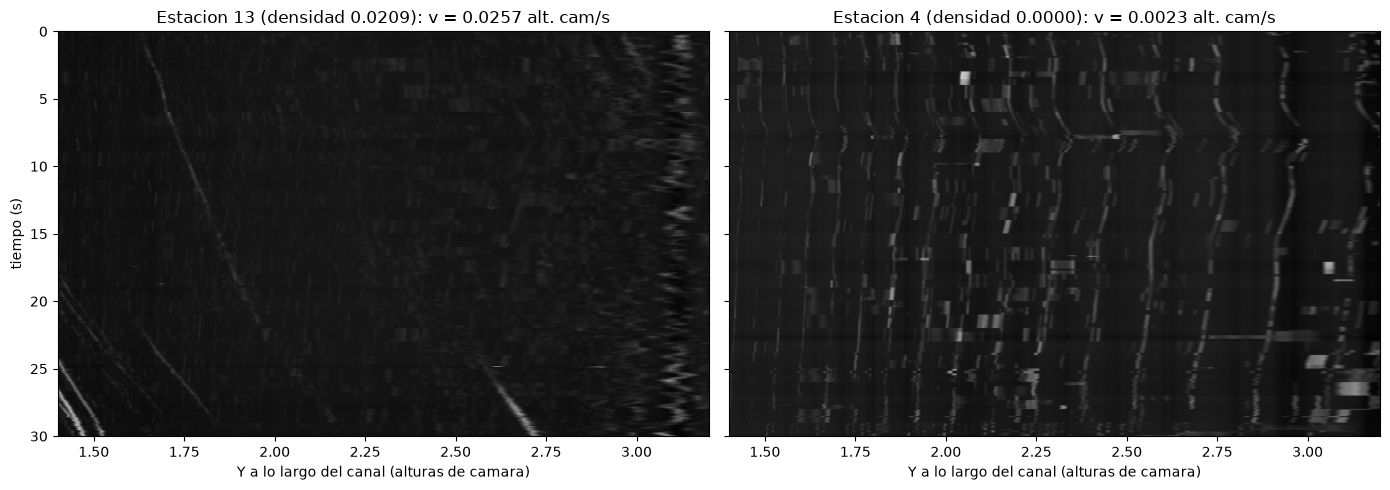

In [6]:
# [v8] Celda nueva: por que hace falta la seleccion por senal. La misma medida, votando todos
# los bloques (como hasta la v7).
sin_seleccion = []
for i in range(N_ESTACIONES):
    prep = np.mean([preparar_sti(l) for l in r["sti_crudo"][i]], axis=0)
    m, c = medir_sti(prep, valido=VALIDO[i])
    sin_seleccion.append(m * DS * ESCALA / DT if np.isfinite(m) else np.nan)
print(pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "densidad": DENSIDAD,
                    "votan todos (v7)": sin_seleccion, "solo con particula (v8)": v_stiv})
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))
con_trazador = (DENSIDAD >= 0.004) & (DENSIDAD <= 0.05) & (coherencia >= 0.60)
cociente = np.array(sin_seleccion)[con_trazador] / v_stiv[con_trazador]
print(f"\nEn las {int(con_trazador.sum())} estaciones con trazador, votando todos los bloques la "
      f"velocidad cambia entre {100 * (cociente.min() - 1):+.0f} % y {100 * (cociente.max() - 1):+.0f} % "
      f"({int((cociente < 0.95).sum())} de ellas, mas de un 5 % por debajo): el residuo estatico "
      "(estelas verticales, v = 0) tira de la mediana hacia cero.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for k, i in enumerate((int(np.nanargmax(DENSIDAD[:-1])), 4)):
    ax[k].imshow(r["sti_prep"][i], cmap="gray", aspect="auto",
                 extent=(YMIN, YMAX, r["sti_prep"].shape[1] * DT, 0))
    ax[k].set_title(f"Estacion {i} (densidad {DENSIDAD[i]:.4f}): v = {v_stiv[i]:.4f} alt. cam/s")
    ax[k].set_xlabel("Y a lo largo del canal (alturas de camara)")
ax[0].set_ylabel("tiempo (s)")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig3_sti.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Control de calidad

La trampa del cero estatico, otra vez, y otro sintoma: agua con y sin trazador tienen el **mismo
brillo y el mismo contraste**, porque el codec aplana el agua turbia por igual. Lo que las separa es
la **densidad de trazador**: la fraccion de posiciones y fotogramas en la que alguna linea de la
banda ve una particula. Agua sin trazador < 0.0004; con trazador 0.006-0.020; la orilla de hormigon
mojado 0.078. Dos umbrales: **0.004** (por debajo no hay nada que medir) y **0.05** (por encima es
orilla).

La **coherencia** baja a 0.60, leida del hueco igual que el contraste de la v4 y la v5: las estaciones
con detritos dan 0.63-0.78 y las que no tienen trazador, o dan una medida no fisica, 0.26-0.52. El 0.70 de la v3 cortaria dentro
de la poblacion buena.

**No se rellena**: aqui tampoco hay seccion. Las estaciones sin trazador son agua, simplemente agua
sin nada que seguir: no se miden.

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterios de aceptacion
# ---------------------------------------------------------------------------------------
# [v8] Coherencia mediana minima: el hueco esta entre 0.52 (sin trazador) y 0.63 (con el).
COH_MIN_ESTACION = 0.60
# Desactivado desde la v6.
CONTRASTE_MIN = 0.0
# Desactivado desde la v7.
BRILLO_MAX_AGUA = 255.0
# Fraccion minima de la linea dentro del fotograma.
COBERTURA_MIN = 0.50
# [v8] Densidad de trazador: agua sin trazador < 0.0004, con trazador 0.006-0.020, orilla 0.078.
DENSIDAD_MIN, DENSIDAD_MAX = 0.004, 0.05
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 4b: control de calidad"):
    es_estatica = r["contraste"] < CONTRASTE_MIN
    es_orilla = r["brillo"] > BRILLO_MAX_AGUA
    fuera = COBERTURA < COBERTURA_MIN
    sin_trazador = DENSIDAD < DENSIDAD_MIN                                           # [v8]
    es_hormigon = DENSIDAD > DENSIDAD_MAX                                            # [v8]
    medida = ((~es_estatica) & (~es_orilla) & (~fuera) & (~sin_trazador) & (~es_hormigon)
              & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv))              # [v8]
    v_eff = np.where(medida, v_stiv, np.nan)

estado = np.where(medida, "medida", np.where(sin_trazador, "sin trazador",
                  np.where(es_hormigon, "orilla (densidad)", "coherencia baja")))
print(f"Estaciones medidas: {int(medida.sum())} de {N_ESTACIONES}: {np.where(medida)[0].tolist()}")
for i in np.where(~medida)[0]:
    print(f"  estacion {i:2d}: {estado[i]} (densidad {DENSIDAD[i]:.5f}, coherencia {coherencia[i]:.3f})")

  [bench] Parte 4b: control de calidad: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 1829 MB
Estaciones medidas: 6 de 15: [8, 9, 10, 11, 12, 13]
  estacion  0: coherencia baja (densidad 0.01582, coherencia 0.522)
  estacion  1: sin trazador (densidad 0.00040, coherencia 0.500)
  estacion  2: sin trazador (densidad 0.00001, coherencia 0.258)
  estacion  3: sin trazador (densidad 0.00003, coherencia 0.404)
  estacion  4: sin trazador (densidad 0.00002, coherencia 0.322)
  estacion  5: sin trazador (densidad 0.00001, coherencia 0.389)
  estacion  6: sin trazador (densidad 0.00001, coherencia 0.343)
  estacion  7: sin trazador (densidad 0.00021, coherencia 0.387)
  estacion 14: orilla (densidad) (densidad 0.10562, coherencia 0.638)


---
## Parte 5 - Perfil transversal, en alturas de camara y en m/s supuestos

Todo lo medido esta en **alturas de camara por segundo**. Pasar a metros exige una longitud real, y
este video no tiene ninguna: se **supone** un ancho de lamina de 5 m. Como el canal mide
`ANCHO_CANAL` alturas de camara, la camara queda a ~2.2 m sobre el agua, coherente con un movil
sostenido desde la pasarela. El dia que se mida el ancho basta con cambiar `ANCHO_LAMINA_M`; medirlo
ademas elimina la dependencia de `FOCAL`.

  [bench] Parte 5: perfil transversal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 1829 MB
Velocidad superficial mediana: 0.0571 alturas de camara/s (6 de 15 estaciones)
Con la escala supuesta (2.222 m por altura de camara): 0.127 m/s


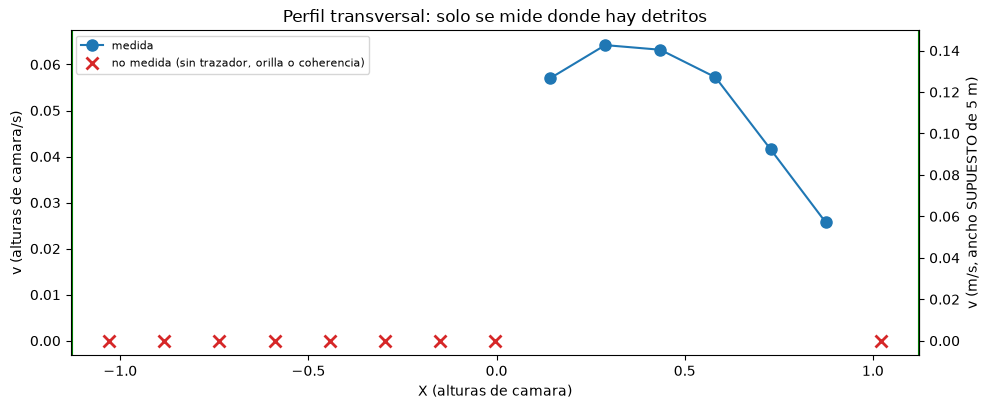

,estacion,X_alt_cam,densidad,coherencia,v_alt_cam_s,v_ms_supuesta,estado
0,0,-1.029356,0.015815,0.522247,NaN,NaN,coherencia baja
1,1,-0.882896,0.000402,0.499967,NaN,NaN,sin trazador
2,2,-0.736436,0.000011,0.258428,NaN,NaN,sin trazador
3,3,-0.589976,0.000026,0.404239,NaN,NaN,sin trazador
4,4,-0.443515,0.000016,0.321877,NaN,NaN,sin trazador
5,5,-0.297055,0.000014,0.389274,NaN,NaN,sin trazador
6,6,-0.150595,0.000009,0.343379,NaN,NaN,sin trazador
7,7,-0.004135,0.000215,0.386601,NaN,NaN,sin trazador
8,8,0.142325,0.006841,0.727902,0.057002,0.126646,medida
9,9,0.288785,0.005756,0.630765,0.064205,0.142650,medida


In [8]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Escala metrica SUPUESTA                                         [v8]
# ---------------------------------------------------------------------------------------
# Ancho de la lamina de agua entre orillas, en metros. NO esta medido.
ANCHO_LAMINA_M = 5.0
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 5: perfil transversal"):
    v_mediana = float(np.nanmedian(v_eff))
    M_POR_ALTURA = ANCHO_LAMINA_M / ANCHO_CANAL                                      # [v8]

print("=" * 60)
print(f"Velocidad superficial mediana: {v_mediana:.4f} alturas de camara/s "
      f"({int(medida.sum())} de {N_ESTACIONES} estaciones)")
print(f"Con la escala supuesta ({M_POR_ALTURA:.3f} m por altura de camara): "
      f"{v_mediana * M_POR_ALTURA:.3f} m/s")                                         # [v8]
print("=" * 60)

perfil = pd.DataFrame({"estacion": np.arange(N_ESTACIONES), "X_alt_cam": X_ESTACIONES,
                       "densidad": DENSIDAD, "coherencia": coherencia,
                       "v_alt_cam_s": v_eff, "v_ms_supuesta": v_eff * M_POR_ALTURA,
                       "estado": estado})
perfil.to_csv(SALIDA_PERFIL, index=False)

import json
config = dict(video=ARCHIVO_VIDEO.name, n_frames=int(r["n_frames"]), fps=FPS, focal=FOCAL,
              punto_fuga=V1.tolist(), cabeceo=CABECEO, guinada=GUINADA,
              ancho_canal_alturas=ANCHO_CANAL, y_min=YMIN, y_max=YMAX,
              n_estaciones=N_ESTACIONES, retranqueo=RETRANQUEO, v_esperada=V_ESPERADA,
              esc_px_por_altura=ESC, ds_px=DS, banda_alturas=ANCHO_BANDA_ALT,
              n_lineas_banda=N_LINEAS_BANDA, lado_bloque=LADO_BLOQUE,
              coh_min_bloque=COH_MIN_BLOQUE, sigma_derivada=SIGMA_DERIVADA,
              cuantil_senal=CUANTIL_SENAL, tophat_k=TOPHAT_K, sigma_previo=SIGMA_PREVIO,
              umbral_particula=UMBRAL_PARTICULA, coh_min_estacion=COH_MIN_ESTACION,
              densidad_min=DENSIDAD_MIN, densidad_max=DENSIDAD_MAX,
              ancho_lamina_m_supuesto=ANCHO_LAMINA_M, v_mediana_alt_cam_s=v_mediana)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(X_ESTACIONES[medida], v_eff[medida], "o-", color="C0", ms=8, label="medida")
ax.plot(X_ESTACIONES[~medida], np.zeros((~medida).sum()), "x", color="C3", ms=9, mew=2,
        label="no medida (sin trazador, orilla o coherencia)")
ax.axvline(X_IZQ, color="g", lw=0.8); ax.axvline(X_DER, color="g", lw=0.8)
ax.set_xlabel("X (alturas de camara)"); ax.set_ylabel("v (alturas de camara/s)")
sec = ax.secondary_yaxis("right", functions=(lambda v: v * M_POR_ALTURA, lambda v: v / M_POR_ALTURA))
sec.set_ylabel("v (m/s, ancho SUPUESTO de 5 m)")
ax.set_title("Perfil transversal: solo se mide donde hay detritos"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_perfil.png", dpi=110, bbox_inches="tight")
plt.show()
perfil

---
## Parte 6 - Recursos consumidos

El video es pequeno (1024x576), pero esta version hace por fotograma lo que ninguna anterior: un
seguimiento de 600 puntos para estabilizar, un top-hat y la rectificacion con un mapa que cambia en
cada fotograma.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 19.1

Tiempo total medido: 118.0 s
Pico de memoria del proceso: 3296 MB


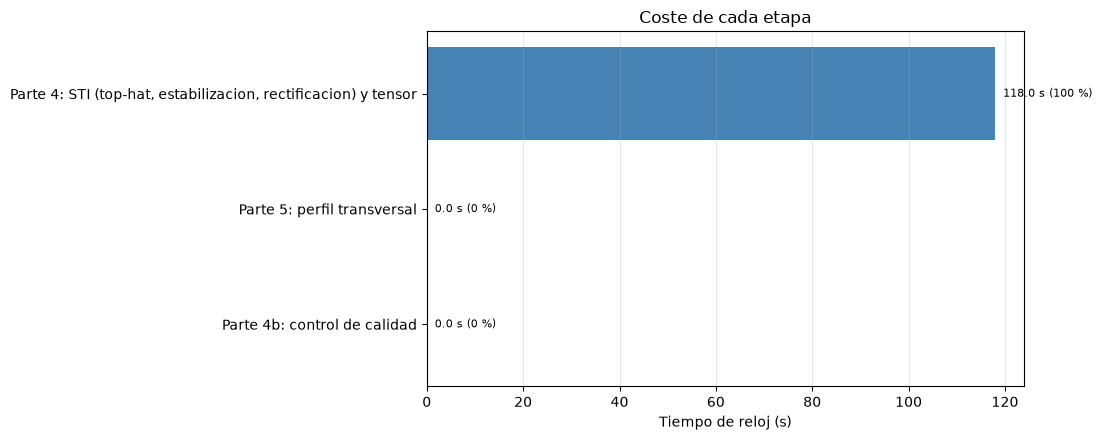

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,"Parte 4: STI (top-hat, estabilizacion, rectifi...",117.97,359.19,3.04,3296.3,1600.5,2429.0,100.0
1,Parte 4b: control de calidad,0.00,0.00,0.00,1828.6,0.0,NaN,0.0
2,Parte 5: perfil transversal,0.00,0.00,0.00,1828.6,0.0,NaN,0.0


In [9]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Referencia

**No hay ninguna.** Ni aforo, ni velocidades de campo, ni una sola longitud medida. En la version
anterior de este caso (`archivo/08_canal_piloto_yaqui/medicion/`) un rastreo de particulas
independiente (PTV) dio r = +0.984 con STIV pero un 13 % mas bajo: eso comprueba la coherencia
interna del metodo, no la velocidad real del agua. Lo unico que se pone al lado es el resultado del
caso original, que **no es una referencia** (es el mismo metodo con otro estimador).

In [10]:
# [v8] Parte nueva: no hay referencia; se anota el caso original solo como contexto.
V_CASO_ORIGINAL = 0.0590      # alturas de camara/s, casos/08_canal_piloto_yaqui (6 de 15 estaciones)
print(f"Esta version:      {v_mediana:.4f} alturas de camara/s ({int(medida.sum())} estaciones)")
print(f"Caso original:     {V_CASO_ORIGINAL:.4f} alturas de camara/s (6 estaciones), "
      f"{100 * (v_mediana / V_CASO_ORIGINAL - 1):+.1f} %, no es una referencia")
resumen = pd.DataFrame([
    dict(concepto="Velocidad superficial mediana", valor=v_mediana, unidad="alturas de camara/s"),
    dict(concepto="Velocidad superficial mediana (escala supuesta)", valor=v_mediana * M_POR_ALTURA,
         unidad="m/s con ancho supuesto de 5 m"),
    dict(concepto="Estaciones medidas", valor=int(medida.sum()), unidad=f"de {N_ESTACIONES}"),
    dict(concepto="Caso original (contexto, no referencia)", valor=V_CASO_ORIGINAL,
         unidad="alturas de camara/s"),
    dict(concepto="Caudal", valor=np.nan, unidad="no calculable: no hay batimetria"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

Esta version:      0.0571 alturas de camara/s (6 estaciones)
Caso original:     0.0590 alturas de camara/s (6 estaciones), -3.2 %, no es una referencia


,concepto,valor,unidad
0,Velocidad superficial mediana,0.057112,alturas de camara/s
1,Velocidad superficial mediana (escala supuesta),0.126890,m/s con ancho supuesto de 5 m
2,Estaciones medidas,6.000000,de 15
3,"Caso original (contexto, no referencia)",0.059000,alturas de camara/s
4,Caudal,NaN,no calculable: no hay batimetria


---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [11]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.3 KiB
  config.json                               0.8 KiB
  fig1_fotograma.png                      295.4 KiB
  fig2_geometria.png                      342.9 KiB
  fig3_sti.png                            297.8 KiB
  fig4_perfil.png                          38.8 KiB
  fig5_recursos.png                        22.4 KiB
  perfil_velocidades.csv                    1.4 KiB
  resumen.csv                               0.3 KiB


---
## Lectura del resultado

**Lo que aporta esta version al codigo**: un realce previo (top-hat) que separa el trazador del codec,
la estabilizacion aplicada al mapa de rectificacion en vez de a la imagen, y la **seleccion de bloques
por senal** en el estimador, la tercera respuesta a la trampa del cero estatico (despues del contraste
de la v4 y el brillo de la v6): ahora no se rechaza la estacion entera, sino que dentro de cada STI
solo votan los bloques que ven una particula.

## Limitaciones conocidas

1. **Los m/s dependen de un ancho supuesto** (5 m): si el canal mide 4, todas las velocidades bajan un
   20 %.
2. **`FOCAL` no se puede medir**: entre 700 y 900 px la velocidad cambia +-9 %. Es un sesgo, no
   dispersion.
3. **Solo se mide donde pasan detritos** (el tercio derecho). El resto del canal no se mide.
4. **Nada valida la magnitud**: no hay ningun dato de campo.
5. **Sin batimetria no hay caudal.**
6. **Balanceo nulo y sin correccion de distorsion de lente**: hipotesis comprobadas solo a ojo.